In [1]:
import numpy as np
import pandas as pd

from utils.dataLoader import loadTrain, loadTest, saveSubmission, splitTrainValidationTest, TEXT_COLUMN, TARGET_COLUMN, ID_COLUMN
from utils.textNormalizer import TextNormalizer, buildViews
from utils.corpusCache import loadOrNormalize
from utils.metrics import compareModels, classificationReport, saveMetrics, loadMetrics

from core.baselineModels import TfidfClassifier
from core.pipeline import ClassificationPipeline
from core.tuning import SvmBlockTuner
from core.optimizers import GreyWolfOptimizer

from utils.plotting import plotConfusionMatrix, plotF1PerClass

In [2]:
trainDf = loadTrain()
testDf = loadTest()
labels = trainDf[TARGET_COLUMN]
trainDf.shape, testDf.shape

((208349, 3), (36768, 2))

In [3]:
normalizer = TextNormalizer()
trainTokens = loadOrNormalize(trainDf[TEXT_COLUMN], normalizer, cacheName='trainLemmas')
testTokens = loadOrNormalize(testDf[TEXT_COLUMN], normalizer, cacheName='testLemmas')

In [4]:
trainViews = buildViews(trainDf[TEXT_COLUMN], trainTokens)
testViews = buildViews(testDf[TEXT_COLUMN], testTokens)
trainViews.head()

,raw,lemmas
0,"hoy y cada día os aplaudimos, igual que cada d...","[aplaudir, dejáis, piel, cuidarno, personal, s..."
1,sesión #diputaciónpermanente con debate conval...,"[sesión, #diputaciónpermanente, debate, conval..."
2,buenos días! imagine dragons - demons (officia...,"[imagine_dragons, demons, official_video, _URL..."
3,desenmascarando al foro de são paulo _url_,"[desenmascarar, foro_de_são_paulo, _URL_]"
4,ayer vimos un ejemplo de lo peor de la polític...,"[ayer, ver, ejemplo, política, insulto, machis..."


In [5]:
featureBlocks = [
    {'view': 'raw', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
    {'view': 'raw', 'analyzer': 'char', 'ngramRange': (1, 6), 'minDf': 3, 'maxFeatures': 1500000},
    {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
]

In [6]:
trainIdx, validationIdx, testIdx = splitTrainValidationTest(labels, 0.15, 0.15, 42)

In [7]:
paramsNbSvm = {
    'featureBlocks': featureBlocks,
    'classifier': 'nbsvm',
    'C': 0.3,
}

In [8]:
modelNbSvm = TfidfClassifier(**paramsNbSvm)
pipelineNbSvm = ClassificationPipeline(model=modelNbSvm)

In [9]:
predictionsNbSvm, actualsNbSvm, metricsNbSvm = pipelineNbSvm.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [10]:
metricsNbSvm

{'accuracy': 0.8358185076155126,
 'precisionMacro': 0.8329576853999876,
 'recallMacro': 0.8303123725350622,
 'f1Macro': 0.8313387350870821,
 'f1PerClass': {'ciudadanos': 0.7881867259447444,
  'podemos': 0.8533141899976071,
  'pp': 0.8064516129032258,
  'psoe': 0.869231261601485,
  'vox': 0.8395098849883484}}

In [11]:
saveMetrics('tfidfNbSvm', metricsNbSvm)

In [12]:
metricsByModel = {name: metrics for name, metrics in loadMetrics().items() if name.startswith('tfidf')}
compareModels(metricsByModel)

,accuracy,precisionMacro,recallMacro,f1Macro,f1 ciudadanos,f1 podemos,f1 pp,f1 psoe,f1 vox
tfidfNbSvm,0.8358,0.8330,0.8303,0.8313,0.7882,0.8533,0.8065,0.8692,0.8395
tfidfSvmRawLemmas,0.8270,0.8236,0.8216,0.8222,0.7723,0.8470,0.8015,0.8629,0.8272
tfidfSvmChars,0.8151,0.8120,0.8100,0.8105,0.7627,0.8305,0.7937,0.8522,0.8134
tfidfSvm,0.8068,0.8036,0.8021,0.8023,0.7584,0.8202,0.7806,0.8445,0.8077
tfidfLogreg,0.7838,0.7792,0.7801,0.7794,0.7338,0.7984,0.7558,0.8256,0.7831


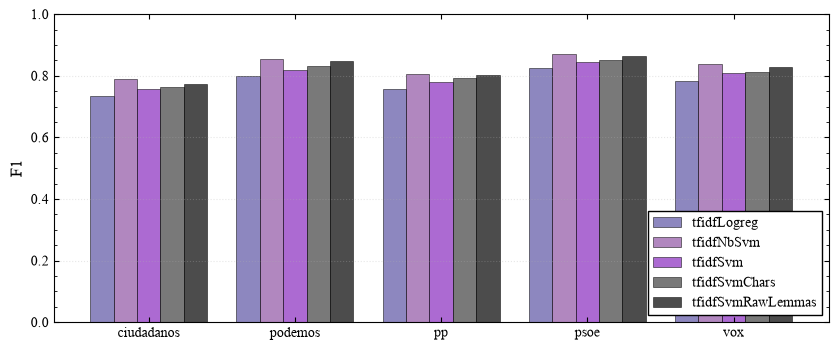

In [13]:
plotF1PerClass(metricsByModel)

In [14]:
predictionsTestSplit, actualsTestSplit, metricsTestSplit = pipelineNbSvm.test(trainViews, labels)
metricsTestSplit

{'accuracy': 0.8354397977794131,
 'precisionMacro': 0.8319140555727584,
 'recallMacro': 0.8294712613993512,
 'f1Macro': 0.8304353291699476,
 'f1PerClass': {'ciudadanos': 0.7827648114901257,
  'podemos': 0.8560903339473052,
  'pp': 0.8010344827586207,
  'psoe': 0.8738000767950851,
  'vox': 0.838486940858601}}

In [15]:
classificationReport(actualsTestSplit, predictionsTestSplit)

,precision,recall,f1-score,support
ciudadanos,0.8122,0.7554,0.7828,4906.0000
podemos,0.8492,0.8631,0.8561,6193.0000
pp,0.7990,0.8031,0.8010,5785.0000
psoe,0.8734,0.8742,0.8738,7809.0000
vox,0.8258,0.8515,0.8385,6560.0000
accuracy,0.8354,0.8354,0.8354,0.8354
macro avg,0.8319,0.8295,0.8304,31253.0000
weighted avg,0.8352,0.8354,0.8351,31253.0000


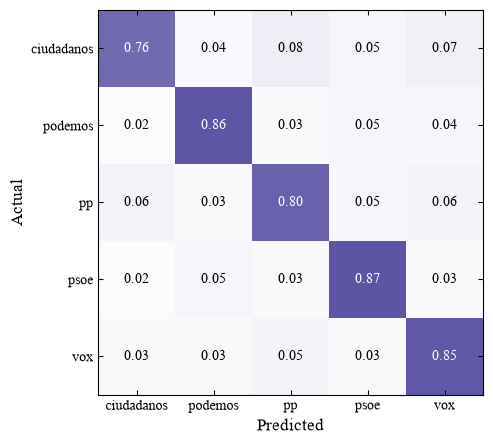

In [16]:
plotConfusionMatrix(actualsTestSplit, predictionsTestSplit)

In [17]:
pipelineNbSvm.fitFull(trainViews, labels)
predictionsTest = pipelineNbSvm.predict(testViews)

In [18]:
submission = saveSubmission(testDf[ID_COLUMN], predictionsTest, 'outputs/submissionTfidfNbSvm.csv')
submission.head()

,id,target
0,3,podemos
1,8,vox
2,9,ciudadanos
3,11,ciudadanos
4,14,ciudadanos


In [19]:
tuner = SvmBlockTuner(
    featureBlocks,
    trainViews.loc[trainIdx],
    labels.loc[trainIdx],
    trainViews.loc[validationIdx],
    labels.loc[validationIdx],
    classifier='nbsvm',
)

In [ ]:
bounds = {
    'logC': (-1.0, 0.0),
    'weight0': (0.5, 2.0),
    'weight1': (0.5, 2.0),
}

In [21]:
optimizer = GreyWolfOptimizer(tuner.objective, bounds, numWolves=6, maxIter=5, numJobs=2, randomSeed=42)
bestSearch, bestError = optimizer.optimize()
bestSearch, 1 - bestError

Iter 1/5 | best error (Alpha): 0.16782411295081057


/Users/sashvqz/Downloads/llms/.venv/lib/python3.11/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Iter 2/5 | best error (Alpha): 0.16782411295081057
Iter 3/5 | best error (Alpha): 0.16662083024284013
Iter 4/5 | best error (Alpha): 0.16662083024284013
Iter 5/5 | best error (Alpha): 0.16662083024284013


({'logC': -0.8646046912165999,
  'weight0': 1.410102437801178,
  'weight1': 1.6020682622511082},
 0.8333791697571599)

In [22]:
pd.DataFrame(tuner.history).sort_values('f1Macro', ascending=False).head(10)

,logC,weight0,weight1,f1Macro
16,-0.864605,1.410102,1.602068,0.833379
26,-0.735352,1.414035,1.685890,0.832890
17,-0.717564,1.070607,1.716075,0.832751
23,-0.670486,1.326703,2.000000,0.832709
19,-0.730882,1.657450,2.000000,0.832693
14,-0.875183,1.031109,2.000000,0.832463
25,-0.762088,1.126726,2.000000,0.832431
27,-0.803254,1.072721,2.000000,0.832415
24,-0.933474,1.193523,1.604672,0.832343
2,-0.549614,1.056197,1.890147,0.832176


In [23]:
paramsTuned = tuner.bestParams(bestSearch)
paramsTuned

{'featureBlocks': [{'view': 'raw',
   'analyzer': 'word',
   'ngramRange': (1, 2),
   'minDf': 2,
   'weight': 1.410102437801178},
  {'view': 'raw',
   'analyzer': 'char',
   'ngramRange': (1, 6),
   'minDf': 3,
   'maxFeatures': 1500000,
   'weight': 1.6020682622511082},
  {'view': 'lemmas',
   'analyzer': 'word',
   'ngramRange': (1, 2),
   'minDf': 2,
   'weight': 1.0}],
 'classifier': 'nbsvm',
 'C': 0.13658257894445197}

In [24]:
del tuner

In [25]:
pipelineTuned = ClassificationPipeline(model=TfidfClassifier(**paramsTuned))
predictionsTuned, actualsTuned, metricsTuned = pipelineTuned.run(trainViews, labels)
metricsTuned

{'accuracy': 0.8378663765519007,
 'precisionMacro': 0.835008544784767,
 'recallMacro': 0.8324006166141672,
 'f1Macro': 0.8333791697571599,
 'f1PerClass': {'ciudadanos': 0.7908060586802246,
  'podemos': 0.8537051792828685,
  'pp': 0.8087309119144164,
  'psoe': 0.872400513478819,
  'vox': 0.8412531854294708}}

In [26]:
predictionsTestTuned, actualsTestTuned, metricsTestTuned = pipelineTuned.test(trainViews, labels)
metricsTestTuned

{'accuracy': 0.8381915336127732,
 'precisionMacro': 0.8348559220502663,
 'recallMacro': 0.8325067126095892,
 'f1Macro': 0.8333926271786319,
 'f1PerClass': {'ciudadanos': 0.7875198307773664,
  'podemos': 0.8590604026845637,
  'pp': 0.804607581879137,
  'psoe': 0.8753370137373219,
  'vox': 0.8404383068147704}}

In [27]:
pipelineTuned.fitFull(trainViews, labels)
submissionTuned = saveSubmission(testDf[ID_COLUMN], pipelineTuned.predict(testViews), 'outputs/submissionTfidfNbSvmTuned.csv')
submissionTuned.head()

,id,target
0,3,podemos
1,8,vox
2,9,ciudadanos
3,11,ciudadanos
4,14,ciudadanos
